In [59]:
import os
from pathlib import Path

# Set writable cache locations before importing Spateo/Numba-backed modules.
os.environ.setdefault("XDG_CACHE_HOME", "/private/tmp/cache-spateo")
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/mpl-spateo")
os.environ.setdefault("NUMBA_CACHE_DIR", "/private/tmp/numba-spateo")

import anndata as ad
import numpy as np
import pandas as pd
import spateo
from spateo.tools.glm import glm_degs


In [97]:

data_dir = Path("../data")
counts_path = "../data/ca3_simulation_gradient/ca3_simulated_dataset_peakt_1_sd.r_2_rep_01.csv"
digitized_path = data_dir / "ca3_xy_digitized.csv"

counts_df = pd.read_csv(counts_path, index_col=0)
digitized_coords = pd.read_csv(digitized_path, index_col=0)

required_digitized_cols = ["xcoord", "ycoord", "spateo_longitudinal", "spateo_radial"]
missing_cols = [col for col in required_digitized_cols if col not in digitized_coords.columns]
if missing_cols:
    raise ValueError(f"Missing columns in {digitized_path}: {missing_cols}")

display(digitized_coords[required_digitized_cols].head())

# The simulated counts CSV is genes x spots; AnnData expects spots x genes.
raw_counts = counts_df.to_numpy(dtype=float).T
gene_names = counts_df.index.astype(str).to_list()

if raw_counts.shape[0] != digitized_coords.shape[0]:
    raise ValueError(
        f"Mismatched spots: counts={raw_counts.shape[0]}, digitized_coords={digitized_coords.shape[0]}"
    )

# Spateo's glm_degs expects size-factor-normalized expression.
library_size = raw_counts.sum(axis=1)
median_library_size = np.median(library_size[library_size > 0])
size_factors = np.where(library_size > 0, library_size / median_library_size, 1.0)
normalized_counts = raw_counts / size_factors[:, None]

obs = pd.DataFrame(
    {
        "xcoord": digitized_coords["xcoord"].to_numpy(),
        "ycoord": digitized_coords["ycoord"].to_numpy(),
        "t": digitized_coords["spateo_longitudinal"].to_numpy(),
        "r": digitized_coords["spateo_radial"].to_numpy(),
        "size_factor": size_factors,
        "library_size": library_size,
    },
    index=[f"spot_{i + 1}" for i in range(raw_counts.shape[0])],
)

adata = ad.AnnData(
    X=normalized_counts,
    obs=obs,
    var=pd.DataFrame(index=gene_names),
)
adata.layers["counts"] = raw_counts
adata.obsm["spatial"] = digitized_coords[["xcoord", "ycoord"]].to_numpy()
adata.var_names_make_unique()

print(adata)
print(f"t range: {adata.obs['t'].min():.4f} to {adata.obs['t'].max():.4f}")
print(f"r range: {adata.obs['r'].min():.4f} to {adata.obs['r'].max():.4f}")


,xcoord,ycoord,spateo_longitudinal,spateo_radial
spot_1,5387.0,2291.6,0.195710,0.953141
spot_2,5408.2,2921.7,0.483782,0.972790
spot_3,5310.4,2941.0,0.497003,0.956435
spot_4,5435.2,2959.8,0.501173,0.982819
spot_5,4476.8,3235.9,0.652313,0.823309


AnnData object with n_obs × n_vars = 1456 × 1000
    obs: 'xcoord', 'ycoord', 't', 'r', 'size_factor', 'library_size'
    obsm: 'spatial'
    layers: 'counts'
t range: 0.0000 to 1.0000
r range: 0.0000 to 1.0000


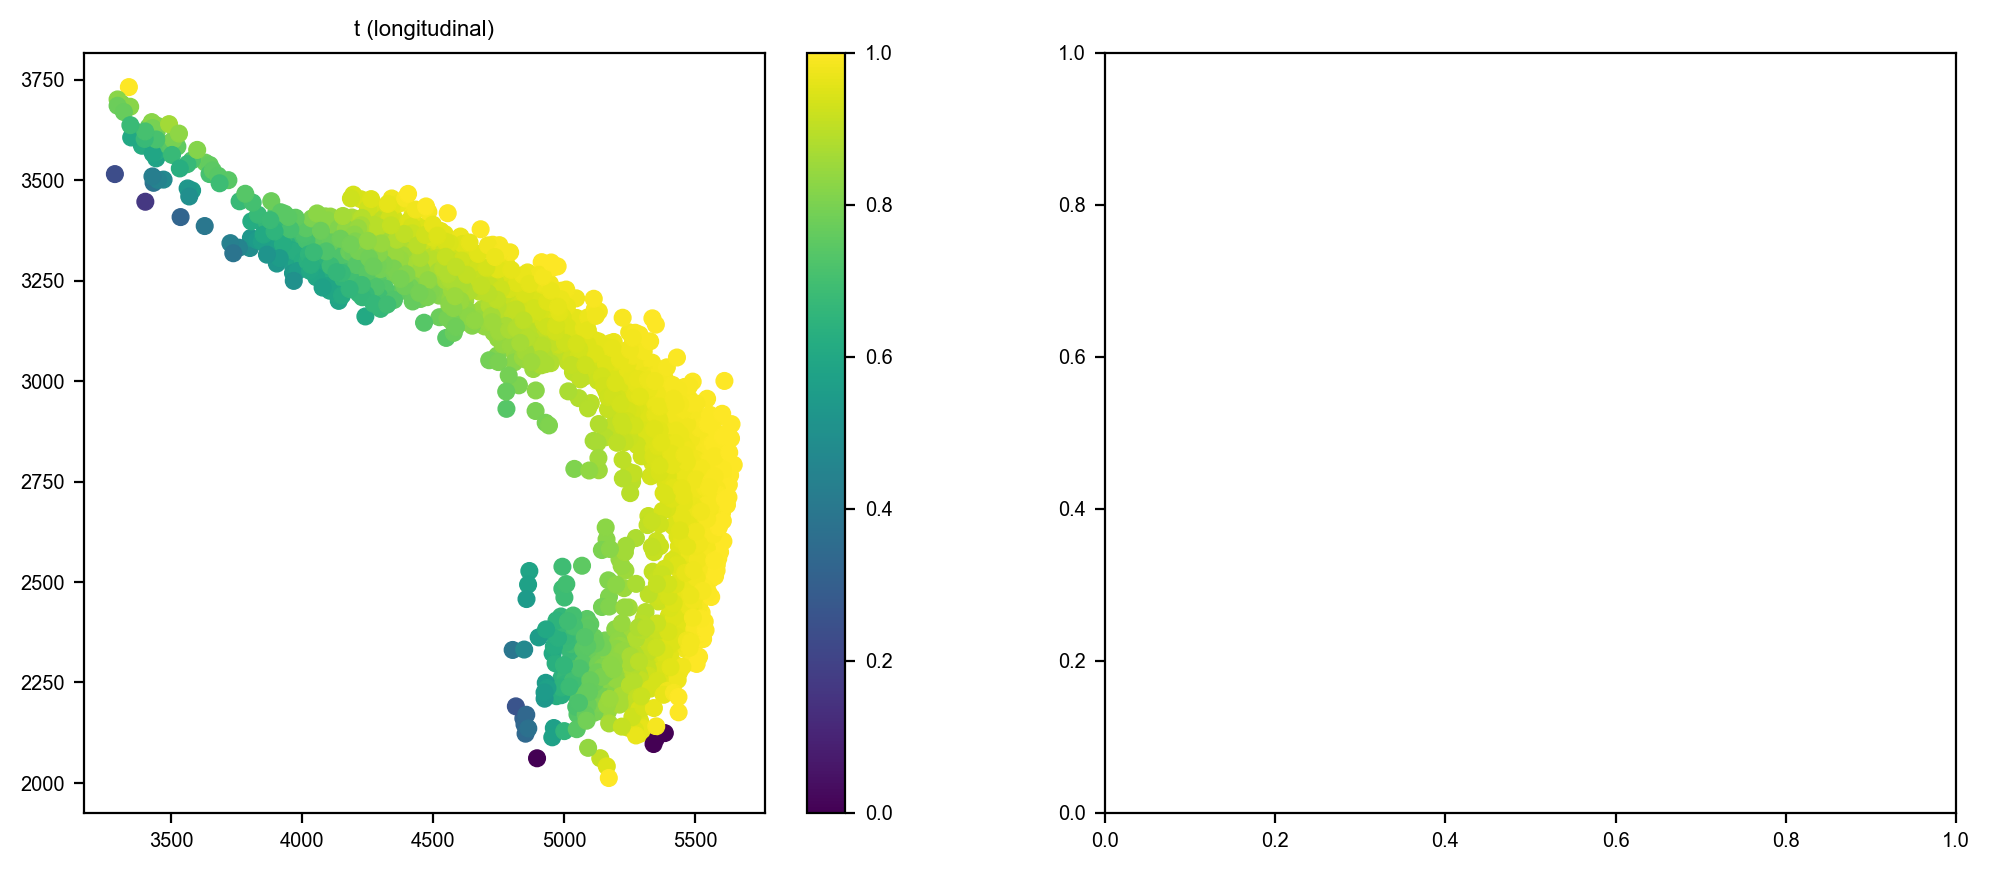

<positron-console-cell-90>:14: UserWarning: Adding colorbar to a different Figure <Figure size 1200x500 with 4 Axes> than <Figure size 600x400 with 0 Axes> which fig.colorbar is called on.


<Figure size 600x400 with 0 Axes>

In [90]:
#Plot t and r to verify they look correct
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc1 = axes[0].scatter(adata.obs["xcoord"], adata.obs["ycoord"], c=adata.obs["r"], cmap="viridis")
axes[0].set
axes[0].set_title("t (longitudinal)")
plt.colorbar(sc1, ax=axes[0])
plt.show()

sc2 = axes[1].scatter(adata.obs["xcoord"], adata.obs["ycoord"], c=adata.obs["r"], cmap="viridis")
axes[1].set_title("r (radial)")
axes[1].set
axes[1].set_title("r (radial)")
plt.colorbar(sc2, ax=axes[1])
plt.show()

In [98]:
glm_key = "glm_degs_t_linear"

import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Negative binomial dispersion parameter alpha not set.*"
    )

    glm_degs(
        adata,
        key_added=glm_key,
        fullModelFormulaStr="~cr(t, df=9) + cr(r, df=5)",
        reducedModelFormulaStr = "~cr(r,df=5)",
        qval_threshold=None,
        llf_threshold=None,
        inplace=True,
    )

glm_hits = adata.uns[glm_key]["glm_result"].copy()
glm_hits.insert(0, "gene", glm_hits.index)
glm_hits = glm_hits.sort_values(["qval", "pval", "log-likelihood"])

print("Top spatially variable genes from Spateo GLM using full model ~t vs reduced model ~1:")
display(glm_hits.head(25))

print("Top hits as text:")
print(glm_hits.head(25).to_string(index=False))

#Find the rank of the gene 1
gene_1_rank = glm_hits.index.get_loc("1") + 1
print(f"Rank of gene_1: {gene_1_rank}")


|-----? Gene expression matrix must be normalized by the size factor, please check if the input gene expression matrix is correct.If you don't have the size factor normalized gene expression matrix, please run `dynamo.pp.normalize_cell_expr_by_size_factors(skip_log = True)`.
|-----> [Detecting genes via Generalized Additive Models (GAMs)] in progress: 9.7000%

/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/family.py:1402: RuntimeWarning: invalid value encountered in divide
  endog_mu = self._clean(endog / mu)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/family.py:1402: RuntimeWarning: divide by zero encountered in divide
  endog_mu = self._clean(endog / mu)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/family.py:1406: RuntimeWarning: divide by zero encountered in log
  resid_dev -= endog_alpha * np.log(endog_alpha / mu_alpha)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/famil

|-----> [Detecting genes via Generalized Additive Models (GAMs)] in progress: 28.0000%

/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/family.py:1402: RuntimeWarning: invalid value encountered in divide
  endog_mu = self._clean(endog / mu)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect 

|-----> [Detecting genes via Generalized Additive Models (GAMs)] in progress: 37.8000%

...

/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/regression/_prediction.py:75: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(self.var_pred_mean)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/genmod/families/links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)


|-----> [Detecting genes via Generalized Additive Models (GAMs)] in progress: 100.0000%
|-----> [Detecting genes via Generalized Additive Models (GAMs)] finished [99.0080s]
Top spatially variable genes from Spateo GLM using full model ~t vs reduced model ~1:


/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/stats/multitest.py:350: RuntimeWarning: invalid value encountered in less_equal
  reject = pvals_sorted <= ecdffactor*alpha
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/stats/multitest.py:356: RuntimeWarning: invalid value encountered in accumulate
  pvals_corrected = np.minimum.accumulate(pvals_corrected_raw[::-1])[::-1]
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/stats/multitest.py:358: RuntimeWarning: invalid value encountered in greater
  pvals_corrected[pvals_corrected>1] = 1
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/statsmodels/stats/multitest.py:268: RuntimeWarning: invalid value encountered in greater
  pvals_corrected[pvals_corrected>1] = 1


,gene,status,family,log-likelihood,pval,qval
709,709,ok,NB2,-144.625168,0.000000e+00,0.000000e+00
161,161,ok,NB2,-5068.134766,4.398676e-42,2.199653e-39
593,593,ok,NB2,-1451.885864,1.058259e-38,3.527529e-36
551,551,ok,NB2,-2546.418457,4.236184e-38,1.059046e-35
603,603,ok,NB2,-1039.754883,2.530838e-34,5.061675e-32
417,417,ok,NB2,-2124.326660,6.052900e-31,1.008817e-28
719,719,ok,NB2,-1344.644897,1.251315e-24,1.787593e-22
919,919,ok,NB2,-942.765381,2.149979e-23,2.687474e-21
231,231,ok,NB2,-841.756592,1.508177e-22,1.675752e-20
395,395,ok,NB2,-1091.014526,4.525379e-22,4.525379e-20


Top hits as text:
gene status family  log-likelihood         pval         qval
 709     ok    NB2     -144.625168 0.000000e+00 0.000000e+00
 161     ok    NB2    -5068.134766 4.398676e-42 2.199653e-39
 593     ok    NB2    -1451.885864 1.058259e-38 3.527529e-36
 551     ok    NB2    -2546.418457 4.236184e-38 1.059046e-35
 603     ok    NB2    -1039.754883 2.530838e-34 5.061675e-32
 417     ok    NB2    -2124.326660 6.052900e-31 1.008817e-28
 719     ok    NB2    -1344.644897 1.251315e-24 1.787593e-22
 919     ok    NB2     -942.765381 2.149979e-23 2.687474e-21
 231     ok    NB2     -841.756592 1.508177e-22 1.675752e-20
 395     ok    NB2    -1091.014526 4.525379e-22 4.525379e-20
 850     ok    NB2     -732.988831 3.217447e-21 2.924951e-19
 995     ok    NB2    -2637.514404 3.776628e-21 3.147190e-19
 713     ok    NB2    -1677.977417 2.240989e-20 1.723838e-18
 706     ok    NB2     -462.064972 3.393597e-20 2.423998e-18
 920     ok    NB2    -2068.164307 9.912520e-20 6.608347e-18
 865  